In [31]:
!pip install pandas numpy scikit-learn matplotlib seaborn xgboost -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.decomposition import PCA

# Classification
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.svm import SVC
from xgboost import XGBClassifier, XGBRegressor
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, confusion_matrix, classification_report,
                              roc_curve, roc_auc_score)

# Régression
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Clustering
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score

import joblib
import warnings
warnings.filterwarnings('ignore')

In [32]:
from google.colab import files
uploaded = files.upload()  # Uploadez train.csv (Loan Prediction dataset)

df = pd.read_csv('/content/Default_Fin.csv')
df.head()

Saving Default_Fin.csv to Default_Fin (1).csv


,Index,Employed,Bank Balance,Annual Salary,Defaulted?
0,1,1,8754.36,532339.56,0
1,2,0,9806.16,145273.56,0
2,3,1,12882.60,381205.68,0
3,4,1,6351.00,428453.88,0
4,5,1,9427.92,461562.00,0


In [33]:
print("Dimensions :", df.shape)
df.info()
print("\nValeurs manquantes :\n", df.isnull().sum())
print("\nRépartition Defaulted? :\n", df['Defaulted?'].value_counts())

Dimensions : (10000, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Index          10000 non-null  int64  
 1   Employed       10000 non-null  int64  
 2   Bank Balance   10000 non-null  float64
 3   Annual Salary  10000 non-null  float64
 4   Defaulted?     10000 non-null  int64  
dtypes: float64(2), int64(3)
memory usage: 390.8 KB

Valeurs manquantes :
 Index            0
Employed         0
Bank Balance     0
Annual Salary    0
Defaulted?       0
dtype: int64

Répartition Defaulted? :
 Defaulted?
0    9667
1     333
Name: count, dtype: int64


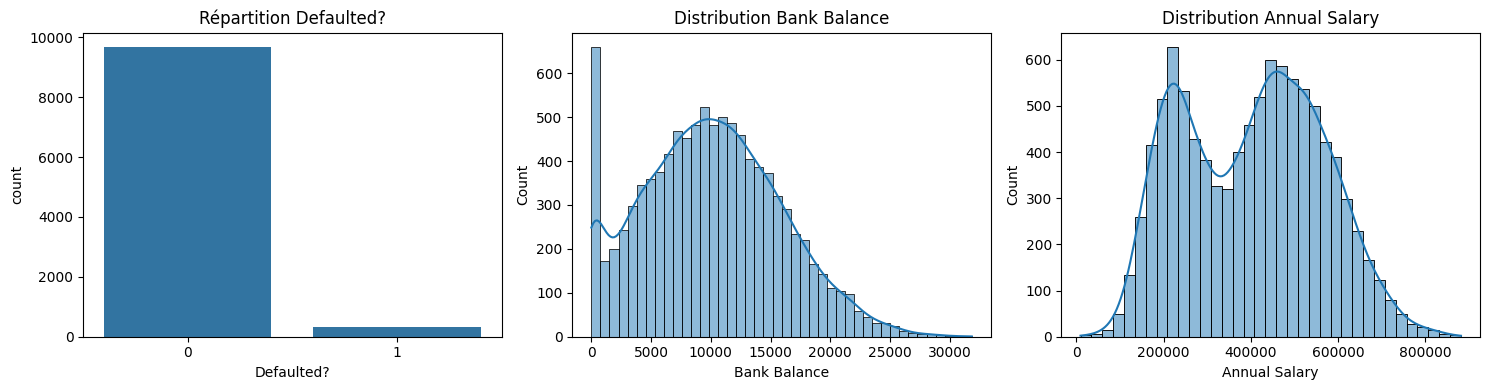

In [34]:
fig, axes = plt.subplots(1, 3, figsize=(15,4))
sns.countplot(x='Defaulted?', data=df, ax=axes[0])
axes[0].set_title("Répartition Defaulted?")
sns.histplot(df['Bank Balance'], kde=True, ax=axes[1])
axes[1].set_title("Distribution Bank Balance")
sns.histplot(df['Annual Salary'], kde=True, ax=axes[2])
axes[2].set_title("Distribution Annual Salary")
plt.tight_layout()
plt.show()

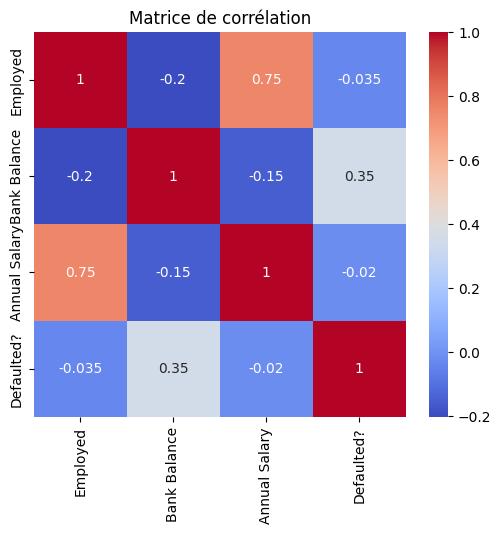

In [35]:
plt.figure(figsize=(6,5))
sns.heatmap(df.drop('Index', axis=1).corr(), annot=True, cmap='coolwarm')
plt.title("Matrice de corrélation")
plt.show()

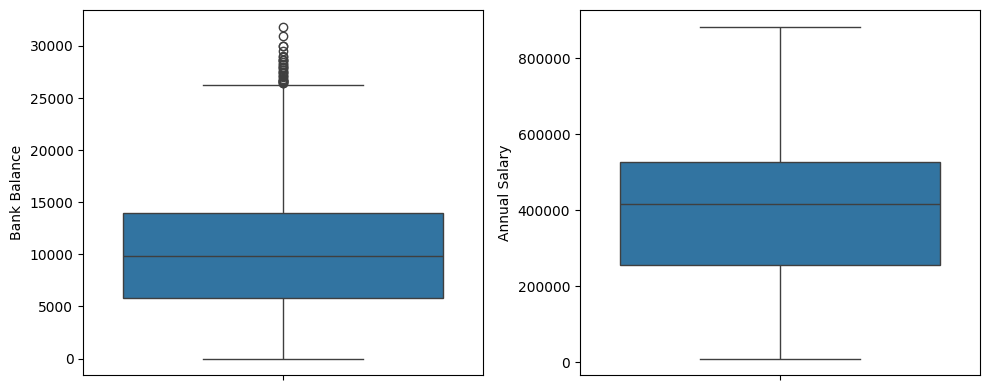

In [36]:
# Boxplots pour détecter les outliers
fig, axes = plt.subplots(1, 2, figsize=(10,4))
sns.boxplot(y=df['Bank Balance'], ax=axes[0])
sns.boxplot(y=df['Annual Salary'], ax=axes[1])
plt.tight_layout()
plt.show()

In [37]:
df.drop('Index', axis=1, inplace=True)

# Vérification finale des valeurs manquantes
print("Valeurs manquantes restantes :", df.isnull().sum().sum())
df.head()

Valeurs manquantes restantes : 0


,Employed,Bank Balance,Annual Salary,Defaulted?
0,1,8754.36,532339.56,0
1,0,9806.16,145273.56,0
2,1,12882.60,381205.68,0
3,1,6351.00,428453.88,0
4,1,9427.92,461562.00,0


#**CLASSIFICATION**

# Préparation X / y

In [38]:
X_clf = df.drop('Defaulted?', axis=1)
y_clf = df['Defaulted?']

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_clf, y_clf, test_size=0.2, random_state=42, stratify=y_clf
)

scaler_clf = StandardScaler()
X_train_c_scaled = scaler_clf.fit_transform(X_train_c)
X_test_c_scaled = scaler_clf.transform(X_test_c)

In [39]:
# si déséquilibre fort (ex: 95%/5%)
!pip install imbalanced-learn -q
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train_c_scaled, y_train_c = smote.fit_resample(X_train_c_scaled, y_train_c)
print("Nouvelle répartition après SMOTE :", pd.Series(y_train_c).value_counts())

Nouvelle répartition après SMOTE : Defaulted?
0    7734
1    7734
Name: count, dtype: int64


Entraînement de plusieurs modèles

In [40]:
models_clf = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight='balanced'),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42, class_weight='balanced'),
    "SVM": SVC(probability=True, random_state=42, class_weight='balanced'),
    "XGBoost": XGBClassifier(eval_metric='logloss', random_state=42)
}

results_clf = {}
for name, model in models_clf.items():
    model.fit(X_train_c_scaled, y_train_c)
    y_pred = model.predict(X_test_c_scaled)
    y_proba = model.predict_proba(X_test_c_scaled)[:, 1]
    results_clf[name] = {
        "Accuracy": accuracy_score(y_test_c, y_pred),
        "Precision": precision_score(y_test_c, y_pred),
        "Recall": recall_score(y_test_c, y_pred),
        "F1-score": f1_score(y_test_c, y_pred),
        "AUC": roc_auc_score(y_test_c, y_proba)
    }

results_clf_df = pd.DataFrame(results_clf).T
results_clf_df.sort_values("F1-score", ascending=False)

,Accuracy,Precision,Recall,F1-score,AUC
Random Forest,0.9025,0.214286,0.716418,0.329897,0.916995
XGBoost,0.8920,0.195918,0.716418,0.307692,0.919069
Logistic Regression,0.8565,0.174556,0.880597,0.291358,0.948831
SVM,0.8370,0.158311,0.895522,0.269058,0.917343


Visualisation et meilleur modèle

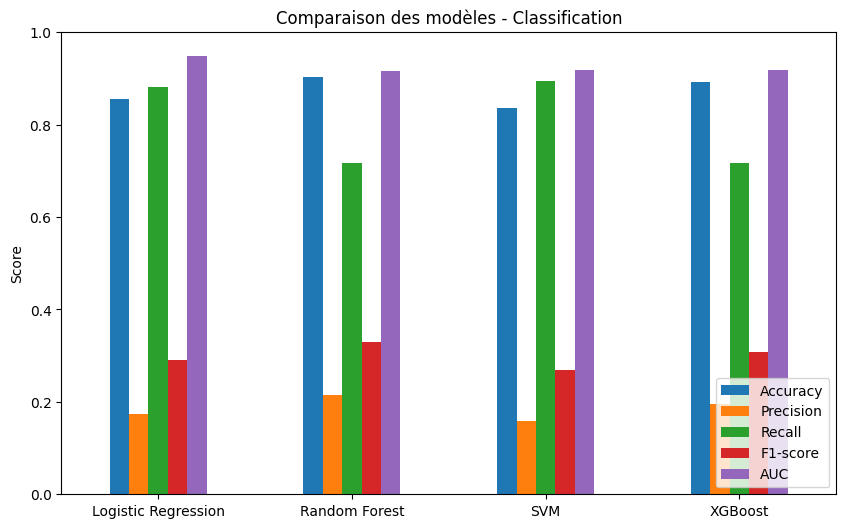

Meilleur modèle Classification : Random Forest


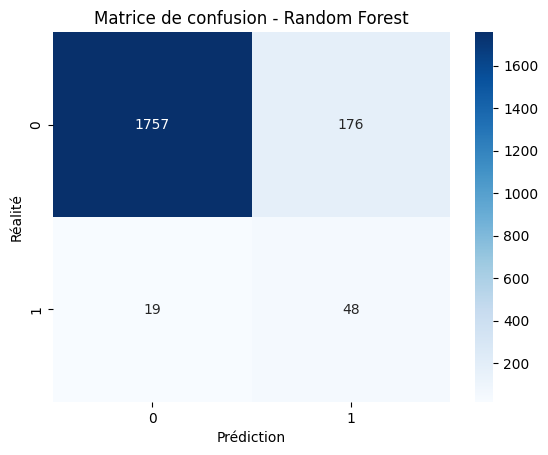

              precision    recall  f1-score   support

           0       0.99      0.91      0.95      1933
           1       0.21      0.72      0.33        67

    accuracy                           0.90      2000
   macro avg       0.60      0.81      0.64      2000
weighted avg       0.96      0.90      0.93      2000



In [41]:
results_clf_df.plot(kind='bar', figsize=(10,6))
plt.title("Comparaison des modèles - Classification")
plt.ylabel("Score"); plt.xticks(rotation=0); plt.ylim(0,1)
plt.legend(loc='lower right')
plt.show()

best_clf_name = results_clf_df["F1-score"].idxmax()
best_clf = models_clf[best_clf_name]
print("Meilleur modèle Classification :", best_clf_name)

y_pred_best = best_clf.predict(X_test_c_scaled)
cm = confusion_matrix(y_test_c, y_pred_best)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title(f"Matrice de confusion - {best_clf_name}")
plt.xlabel("Prédiction"); plt.ylabel("Réalité")
plt.show()

print(classification_report(y_test_c, y_pred_best))

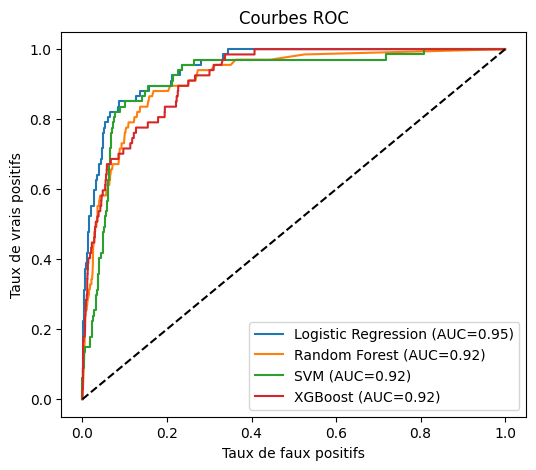

In [42]:
# Courbe ROC
plt.figure(figsize=(6,5))
for name, model in models_clf.items():
    y_proba = model.predict_proba(X_test_c_scaled)[:, 1]
    fpr, tpr, _ = roc_curve(y_test_c, y_proba)
    auc = roc_auc_score(y_test_c, y_proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.2f})")
plt.plot([0,1],[0,1],'k--')
plt.xlabel("Taux de faux positifs"); plt.ylabel("Taux de vrais positifs")
plt.title("Courbes ROC"); plt.legend()
plt.show()

Sauvegarde

In [43]:
joblib.dump(best_clf, 'model_classification.pkl')
joblib.dump(scaler_clf, 'scaler_classification.pkl')

['scaler_classification.pkl']

# **RÉGRESSION (prédire Bank Balance)**

In [44]:
X_reg = df.drop(['Bank Balance', 'Defaulted?'], axis=1)
y_reg = df['Bank Balance']

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)

scaler_reg = StandardScaler()
X_train_r_scaled = scaler_reg.fit_transform(X_train_r)
X_test_r_scaled = scaler_reg.transform(X_test_r)

Entraînement de plusieurs modèles

In [45]:
models_reg = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.1),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42),
    "XGBoost": XGBRegressor(random_state=42)
}

results_reg = {}
for name, model in models_reg.items():
    model.fit(X_train_r_scaled, y_train_r)
    y_pred = model.predict(X_test_r_scaled)
    results_reg[name] = {
        "MAE": mean_absolute_error(y_test_r, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test_r, y_pred)),
        "R2": r2_score(y_test_r, y_pred)
    }

results_reg_df = pd.DataFrame(results_reg).T
results_reg_df.sort_values("R2", ascending=False)

,MAE,RMSE,R2
Ridge,4607.015751,5681.944468,0.023937
Lasso,4607.017535,5681.945509,0.023936
Linear Regression,4607.020721,5681.958942,0.023932
XGBoost,4704.151073,5808.852848,-0.020152
Random Forest,5567.888954,6917.885070,-0.446874


Visualisation et meilleur modèle

Meilleur modèle Régression : Ridge


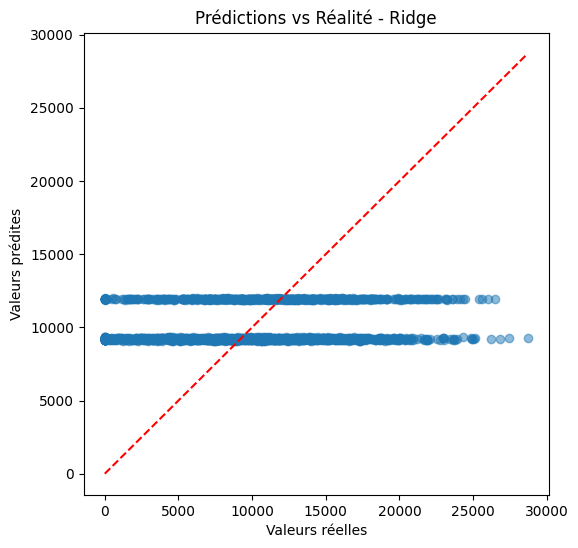

In [46]:
best_reg_name = results_reg_df["R2"].idxmax()
best_reg = models_reg[best_reg_name]
print("Meilleur modèle Régression :", best_reg_name)

y_pred_best_r = best_reg.predict(X_test_r_scaled)

plt.figure(figsize=(6,6))
plt.scatter(y_test_r, y_pred_best_r, alpha=0.5)
plt.plot([y_test_r.min(), y_test_r.max()], [y_test_r.min(), y_test_r.max()], 'r--')
plt.xlabel("Valeurs réelles"); plt.ylabel("Valeurs prédites")
plt.title(f"Prédictions vs Réalité - {best_reg_name}")
plt.show()

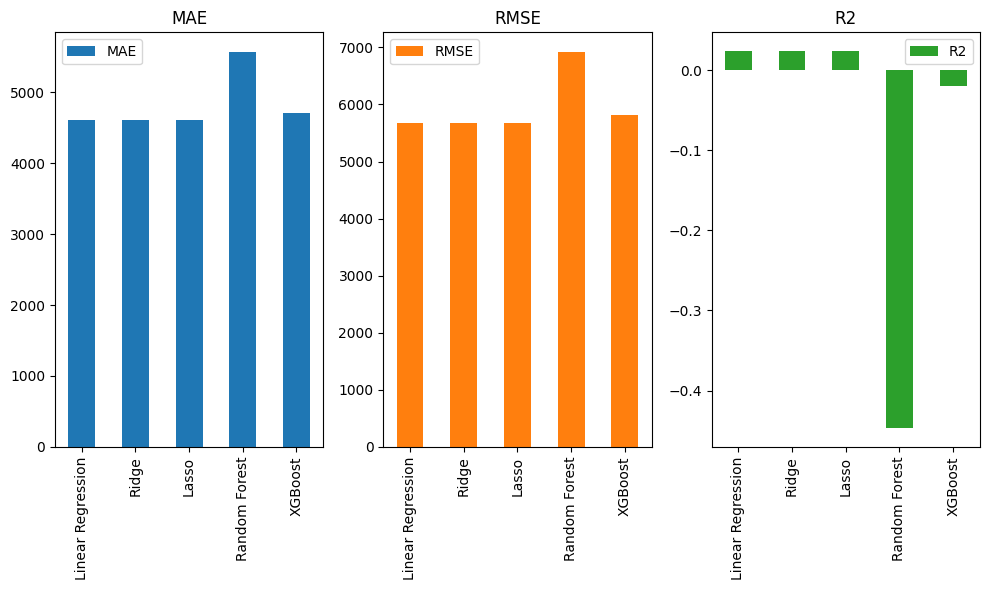

In [47]:
results_reg_df.plot(kind='bar', figsize=(10,6), subplots=True, layout=(1,3))
plt.tight_layout()
plt.show()

 Sauvegarde

In [48]:
joblib.dump(best_reg, 'model_regression.pkl')
joblib.dump(scaler_reg, 'scaler_regression.pkl')

['scaler_regression.pkl']

# **CLUSTERING (segmentation des clients)**

Sélection des variables et standardisation

In [49]:
cluster_features = ['Employed', 'Bank Balance', 'Annual Salary']
X_cluster = df[cluster_features]

scaler_cluster = StandardScaler()
X_cluster_scaled = scaler_cluster.fit_transform(X_cluster)

Nombre optimal de clusters

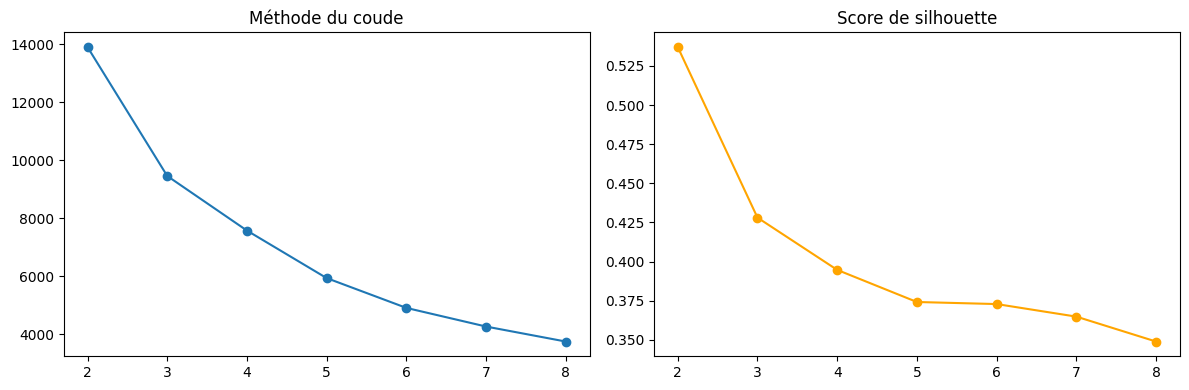

In [50]:
inertias = []
silhouette_scores = []
K_range = range(2, 9)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_cluster_scaled)
    inertias.append(km.inertia_)
    silhouette_scores.append(silhouette_score(X_cluster_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(12,4))
axes[0].plot(K_range, inertias, marker='o')
axes[0].set_title("Méthode du coude")
axes[1].plot(K_range, silhouette_scores, marker='o', color='orange')
axes[1].set_title("Score de silhouette")
plt.tight_layout()
plt.show()

Application de K-Means


In [51]:
k_optimal = 3  # ajustez selon le graphique
kmeans = KMeans(n_clusters=k_optimal, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_cluster_scaled)

print(df['Cluster'].value_counts())

Cluster
0    3734
2    3317
1    2949
Name: count, dtype: int64


**Visualisation (PCA 2D)**

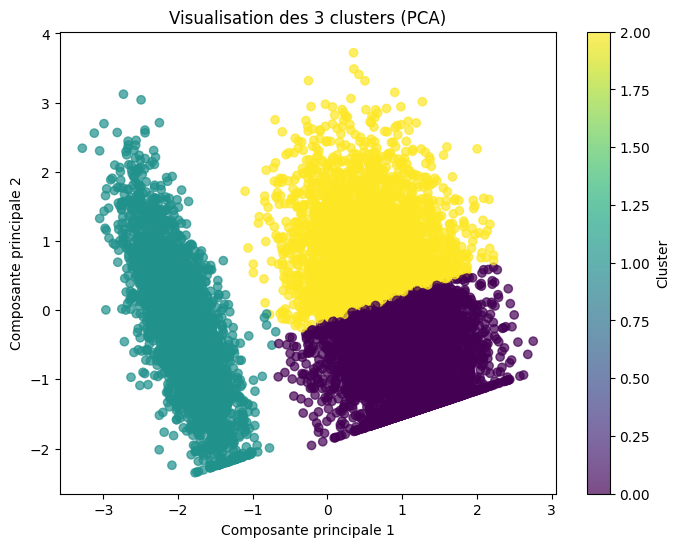

In [52]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_cluster_scaled)

plt.figure(figsize=(8,6))
scatter = plt.scatter(X_pca[:,0], X_pca[:,1], c=df['Cluster'], cmap='viridis', alpha=0.7)
plt.xlabel("Composante principale 1"); plt.ylabel("Composante principale 2")
plt.title(f"Visualisation des {k_optimal} clusters (PCA)")
plt.colorbar(scatter, label='Cluster')
plt.show()

In [53]:
# Interprétation des clusters
cluster_profile = df.groupby('Cluster')[cluster_features + ['Defaulted?']].mean()
print("Profil moyen par cluster :")
cluster_profile

Profil moyen par cluster :


,Employed,Bank Balance,Annual Salary,Defaulted?
Cluster,,,,
0,1.000000,4914.667359,480759.691398,0.000803
1,0.001695,11851.556826,215236.016480,0.043065
2,1.000000,14152.359433,479997.021996,0.061200


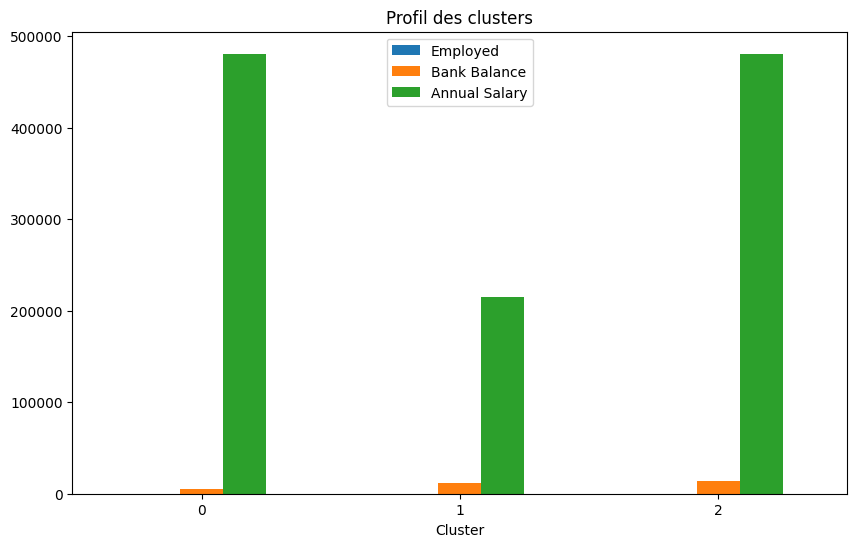

In [54]:
cluster_profile[cluster_features].plot(kind='bar', figsize=(10,6))
plt.title("Profil des clusters")
plt.xticks(rotation=0)
plt.show()

In [55]:
joblib.dump(kmeans, 'model_clustering.pkl')
joblib.dump(scaler_cluster, 'scaler_clustering.pkl')
joblib.dump(pca, 'pca_clustering.pkl')

['pca_clustering.pkl']

In [56]:
 #Téléchargement de tous les modèles
 model_files = [
    'model_classification.pkl', 'scaler_classification.pkl',
    'model_regression.pkl', 'scaler_regression.pkl',
    'model_clustering.pkl', 'scaler_clustering.pkl', 'pca_clustering.pkl'
]

for f in model_files:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [57]:
# Installation
!pip install gradio -q

In [58]:
import joblib
import numpy as np
import gradio as gr

from google.colab import files
uploaded = files.upload()  # sélectionnez tous vos fichiers .pkl

Saving scaler_classification.pkl to scaler_classification (2).pkl


In [59]:
# Chargement des modèles et scalers
model_clf = joblib.load('model_classification.pkl')
scaler_clf = joblib.load('scaler_classification.pkl')

model_reg = joblib.load('model_regression.pkl')
scaler_reg = joblib.load('scaler_regression.pkl')

model_cluster = joblib.load('model_clustering.pkl')
scaler_cluster = joblib.load('scaler_clustering.pkl')
pca_cluster = joblib.load('pca_clustering.pkl')

In [60]:
#Fonctions de prédiction (une par tâche)
def predict_classification(employed, bank_balance, annual_salary):
    X = np.array([[employed, bank_balance, annual_salary]])
    X_scaled = scaler_clf.transform(X)
    pred = model_clf.predict(X_scaled)[0]
    proba = model_clf.predict_proba(X_scaled)[0][1]
    label = "Risque de défaut" if pred == 1 else "Pas de risque de défaut"
    return f"{label} (probabilité de défaut : {proba:.2%})"


def predict_regression(employed, annual_salary):
    X = np.array([[employed, annual_salary]])
    X_scaled = scaler_reg.transform(X)
    pred = model_reg.predict(X_scaled)[0]
    return f"Solde bancaire estimé : {pred:,.2f} $"


def predict_clustering(employed, bank_balance, annual_salary):
    X = np.array([[employed, bank_balance, annual_salary]])
    X_scaled = scaler_cluster.transform(X)
    cluster = model_cluster.predict(X_scaled)[0]
    return f"Ce client appartient au segment / cluster : {cluster}"

In [61]:
print("Classification - colonnes dans l'ordre :", list(X_clf.columns))
print("Régression - colonnes dans l'ordre :", list(X_reg.columns))
print("Clustering - colonnes dans l'ordre :", list(X_cluster.columns))

Classification - colonnes dans l'ordre : ['Employed', 'Bank Balance', 'Annual Salary']
Régression - colonnes dans l'ordre : ['Employed', 'Annual Salary']
Clustering - colonnes dans l'ordre : ['Employed', 'Bank Balance', 'Annual Salary']


In [62]:
print("Modèle chargé :", model_cluster)
print("Scaler chargé :", scaler_cluster)
print("Colonnes attendues par le scaler :", scaler_cluster.feature_names_in_ if hasattr(scaler_cluster, 'feature_names_in_') else "non disponible")

Modèle chargé : KMeans(n_clusters=3, n_init=10, random_state=42)
Scaler chargé : StandardScaler()
Colonnes attendues par le scaler : ['Employed' 'Bank Balance' 'Annual Salary']


In [63]:
print("Modèle chargé :", model_cluster)
print("Scaler chargé :", scaler_cluster)
print("Colonnes attendues par le scaler :", scaler_cluster.feature_names_in_ if hasattr(scaler_cluster, 'feature_names_in_') else "non disponible")

Modèle chargé : KMeans(n_clusters=3, n_init=10, random_state=42)
Scaler chargé : StandardScaler()
Colonnes attendues par le scaler : ['Employed' 'Bank Balance' 'Annual Salary']


In [64]:
with gr.Blocks(title="FinRisk Analytics") as demo:
    gr.Markdown("# 🏦 FinRisk Analytics — Analyse de Risque Financier")

    with gr.Tab("🔮 Classification (Risque de défaut)"):
        gr.Markdown("Prédire si un client risque de faire défaut sur son crédit.")
        employed_c = gr.Radio([0, 1], label="Employed (0=Non, 1=Oui)", value=1)
        balance_c = gr.Number(label="Bank Balance", value=5000)
        salary_c = gr.Number(label="Annual Salary", value=40000)
        btn_c = gr.Button("Prédire")
        output_c = gr.Textbox(label="Résultat")
        btn_c.click(fn=predict_classification,
                    inputs=[employed_c, balance_c, salary_c],
                    outputs=output_c)

    with gr.Tab("📈 Régression (Bank Balance)"):
        gr.Markdown("Estimer le solde bancaire d'un client.")
        employed_r = gr.Radio([0, 1], label="Employed (0=Non, 1=Oui)", value=1)
        salary_r = gr.Number(label="Annual Salary", value=40000)
        btn_r = gr.Button("Prédire")
        output_r = gr.Textbox(label="Résultat")
        btn_r.click(fn=predict_regression,
                    inputs=[employed_r, salary_r],
                    outputs=output_r)

    with gr.Tab("🧩 Clustering (Segmentation client)"):
        gr.Markdown("Identifier le segment auquel appartient un client.")
        employed_k = gr.Radio([0, 1], label="Employed (0=Non, 1=Oui)", value=1)
        balance_k = gr.Number(label="Bank Balance", value=5000)
        salary_k = gr.Number(label="Annual Salary", value=40000)
        btn_k = gr.Button("Prédire")
        output_k = gr.Textbox(label="Résultat")
        btn_k.click(fn=predict_clustering,
                    inputs=[employed_k, balance_k, salary_k],
                    outputs=output_k)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://5aebfef7ce6418d1c3.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [65]:
import os
print(os.listdir())

['.config', 'Default_Fin (1).csv', 'pca_clustering.pkl', '.gradio', 'model_clustering.pkl', 'scaler_classification (1).pkl', 'scaler_clustering.pkl', 'model_classification.pkl', 'scaler_classification.pkl', 'scaler_classification (2).pkl', 'model_regression.pkl', 'scaler_regression.pkl', 'Default_Fin.csv', 'sample_data']


In [ ]:
from google.colab import files
uploaded = files.upload()  # sélectionnez uniquement model_regression.pkl et scaler_regression.pkl

In [ ]:
import os
required_files = [
    'model_classification.pkl', 'scaler_classification.pkl',
    'model_regression.pkl', 'scaler_regression.pkl',
    'model_clustering.pkl', 'scaler_clustering.pkl', 'pca_clustering.pkl'
]
for f in required_files:
    print(f, "✅ présent" if os.path.exists(f) else "❌ MANQUANT")

In [ ]:
# Rappel des cellules R1 à R4 - à exécuter dans l'ordre si les fichiers sont introuvables

X_reg = df.drop(['Bank Balance', 'Defaulted?'], axis=1)
y_reg = df['Bank Balance']

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)

scaler_reg = StandardScaler()
X_train_r_scaled = scaler_reg.fit_transform(X_train_r)
X_test_r_scaled = scaler_reg.transform(X_test_r)

models_reg = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.1),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42),
    "XGBoost": XGBRegressor(random_state=42)
}

results_reg = {}
for name, model in models_reg.items():
    model.fit(X_train_r_scaled, y_train_r)
    y_pred = model.predict(X_test_r_scaled)
    results_reg[name] = {
        "MAE": mean_absolute_error(y_test_r, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test_r, y_pred)),
        "R2": r2_score(y_test_r, y_pred)
    }

results_reg_df = pd.DataFrame(results_reg).T
best_reg_name = results_reg_df["R2"].idxmax()
best_reg = models_reg[best_reg_name]

joblib.dump(best_reg, 'model_regression.pkl')
joblib.dump(scaler_reg, 'scaler_regression.pkl')

print("Fichiers régénérés avec succès :", best_reg_name)

In [ ]:
for f in required_files:
    print(f, "✅ présent" if os.path.exists(f) else "❌ MANQUANT")

In [ ]:
from google.colab import files
uploaded = files.upload()  # sélectionnez uniquement model_regression.pkl et scaler_regression.pkl

In [ ]:
# Rappel des cellules R1 à R4 - à exécuter dans l'ordre si les fichiers sont introuvables

X_reg = df.drop(['Bank Balance', 'Defaulted?'], axis=1)
y_reg = df['Bank Balance']

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)

scaler_reg = StandardScaler()
X_train_r_scaled = scaler_reg.fit_transform(X_train_r)
X_test_r_scaled = scaler_reg.transform(X_test_r)

models_reg = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.1),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42),
    "XGBoost": XGBRegressor(random_state=42)
}

results_reg = {}
for name, model in models_reg.items():
    model.fit(X_train_r_scaled, y_train_r)
    y_pred = model.predict(X_test_r_scaled)
    results_reg[name] = {
        "MAE": mean_absolute_error(y_test_r, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test_r, y_pred)),
        "R2": r2_score(y_test_r, y_pred)
    }

results_reg_df = pd.DataFrame(results_reg).T
best_reg_name = results_reg_df["R2"].idxmax()
best_reg = models_reg[best_reg_name]

joblib.dump(best_reg, 'model_regression.pkl')
joblib.dump(scaler_reg, 'scaler_regression.pkl')

print("Fichiers régénérés avec succès :", best_reg_name)

In [ ]:
for f in required_files:
    print(f, "✅ présent" if os.path.exists(f) else "❌ MANQUANT")